Agent: Claude Opus 5.5 Medium

Prompt: read and understand the dataset in this folder before we begin and
        install pandas and numpy in the current venv

In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv('card_transdata.csv')

Prompt: in @fraud.ipynb , for the loaded dataset print the first few rows, missing values, and summary statistics. each in its own cell

In [3]:
data.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


In [4]:
data.isna().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

In [5]:
data.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


Prompt: since we have few missing values, let's drop them and store the new clean dataset in a new data_clean dataframe

In [6]:
data_clean = data.dropna().copy()
print(data_clean.shape)
data_clean.isna().sum()

(977, 8)


distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

Prompt: let's explore univariate analysees for all the features in the dataset. (count plots for each, and histograms where necessary)

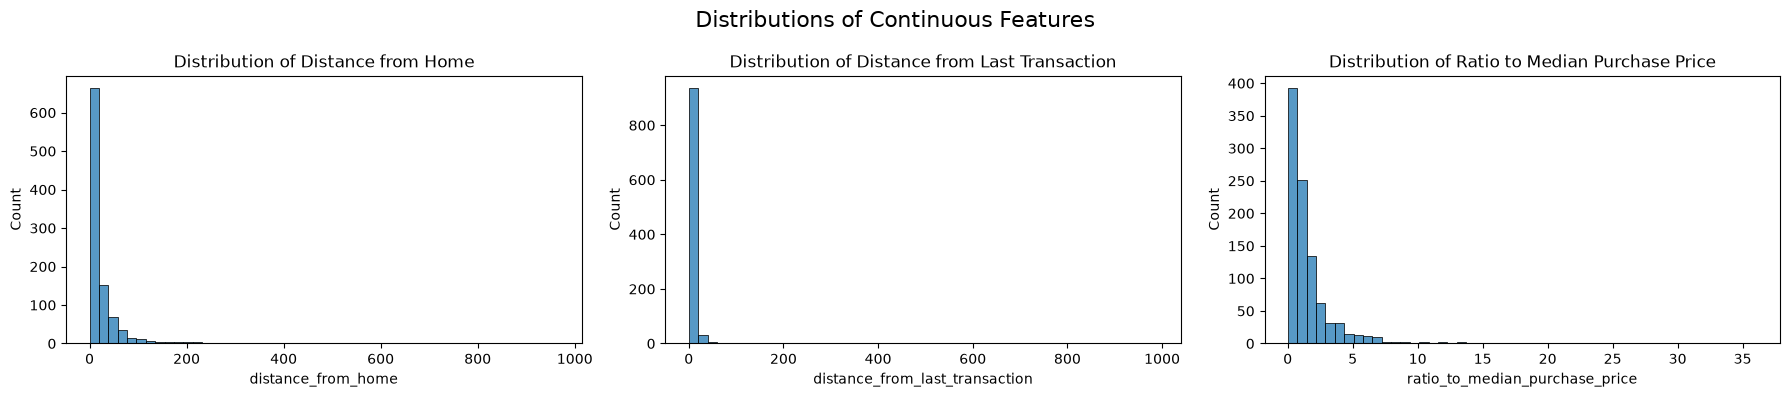

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

continuous = ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price']
binary = ['repeat_retailer', 'used_chip', 'used_pin_number', 'online_order', 'fraud']
names = {
    'distance_from_home': 'Distance from Home',
    'distance_from_last_transaction': 'Distance from Last Transaction',
    'ratio_to_median_purchase_price': 'Ratio to Median Purchase Price',
    'repeat_retailer': 'Repeat Retailer',
    'used_chip': 'Used Chip',
    'used_pin_number': 'Used PIN Number',
    'online_order': 'Online Order',
    'fraud': 'Fraud',
}
fraud_labels = {0: 'Non-fraudulent', 1: 'Fraudulent'}
fraud_palette = {'Non-fraudulent': 'tab:green', 'Fraudulent': 'tab:red'}

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, continuous):
    sns.histplot(data=data_clean, x=col, bins=50, ax=ax)
    ax.set_title(f'Distribution of {names[col]}')
fig.suptitle('Distributions of Continuous Features', fontsize=16)
plt.tight_layout()
plt.show()

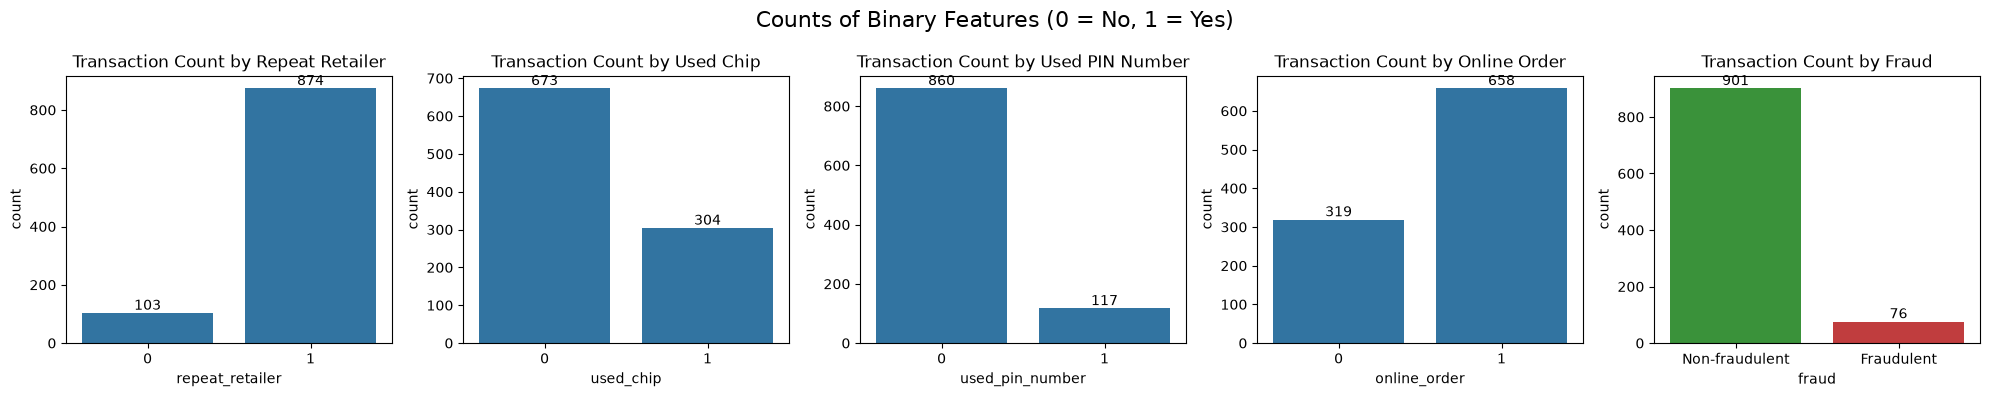

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, binary):
    if col == 'fraud':
        fraud_status = data_clean[col].map(fraud_labels)
        sns.countplot(x=fraud_status, order=list(fraud_palette), hue=fraud_status,
                      palette=fraud_palette, ax=ax)
    else:
        sns.countplot(data=data_clean, x=data_clean[col].astype(int), ax=ax)
    for container in ax.containers:
        ax.bar_label(container)
    ax.set_title(f'Transaction Count by {names[col]}')
fig.suptitle('Counts of Binary Features (0 = No, 1 = Yes)', fontsize=16)
plt.tight_layout()
plt.show()

Prompt: let's now explore bivariate relationships between the features using countplots (using percentanges where relevant and understandable) and scatterplots

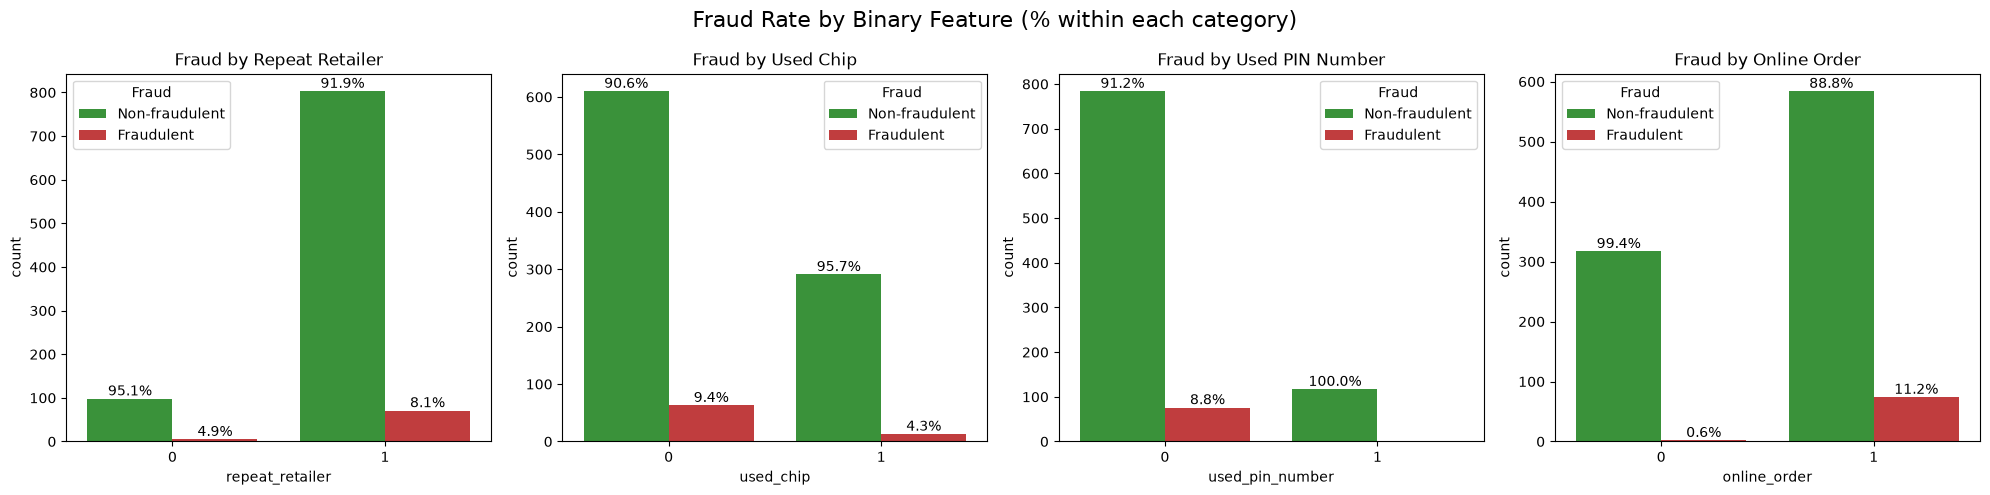

In [9]:
from itertools import combinations

predictors = [c for c in binary if c != 'fraud']

def countplot_with_pct(ax, x, hue):
    hue_values = data_clean[hue].astype(int)
    hue_order, palette = None, None
    if hue == 'fraud':
        hue_values = hue_values.map(fraud_labels)
        hue_order, palette = list(fraud_palette), fraud_palette
    sns.countplot(data=data_clean, x=data_clean[x].astype(int), hue=hue_values,
                  hue_order=hue_order, palette=palette, ax=ax)
    # percentages are within each x category, so bars of the same x sum to 100%
    group_totals = data_clean[x].value_counts().sort_index().values
    for container in ax.containers:
        pct = [h / t * 100 for h, t in zip(container.datavalues, group_totals)]
        ax.bar_label(container, labels=[f'{p:.1f}%' for p in pct])
    ax.set_title(f'{names[hue]} by {names[x]}')
    ax.legend(title=names[hue])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, predictors):
    countplot_with_pct(ax, col, 'fraud')
fig.suptitle('Fraud Rate by Binary Feature (% within each category)', fontsize=16)
plt.tight_layout()
plt.show()

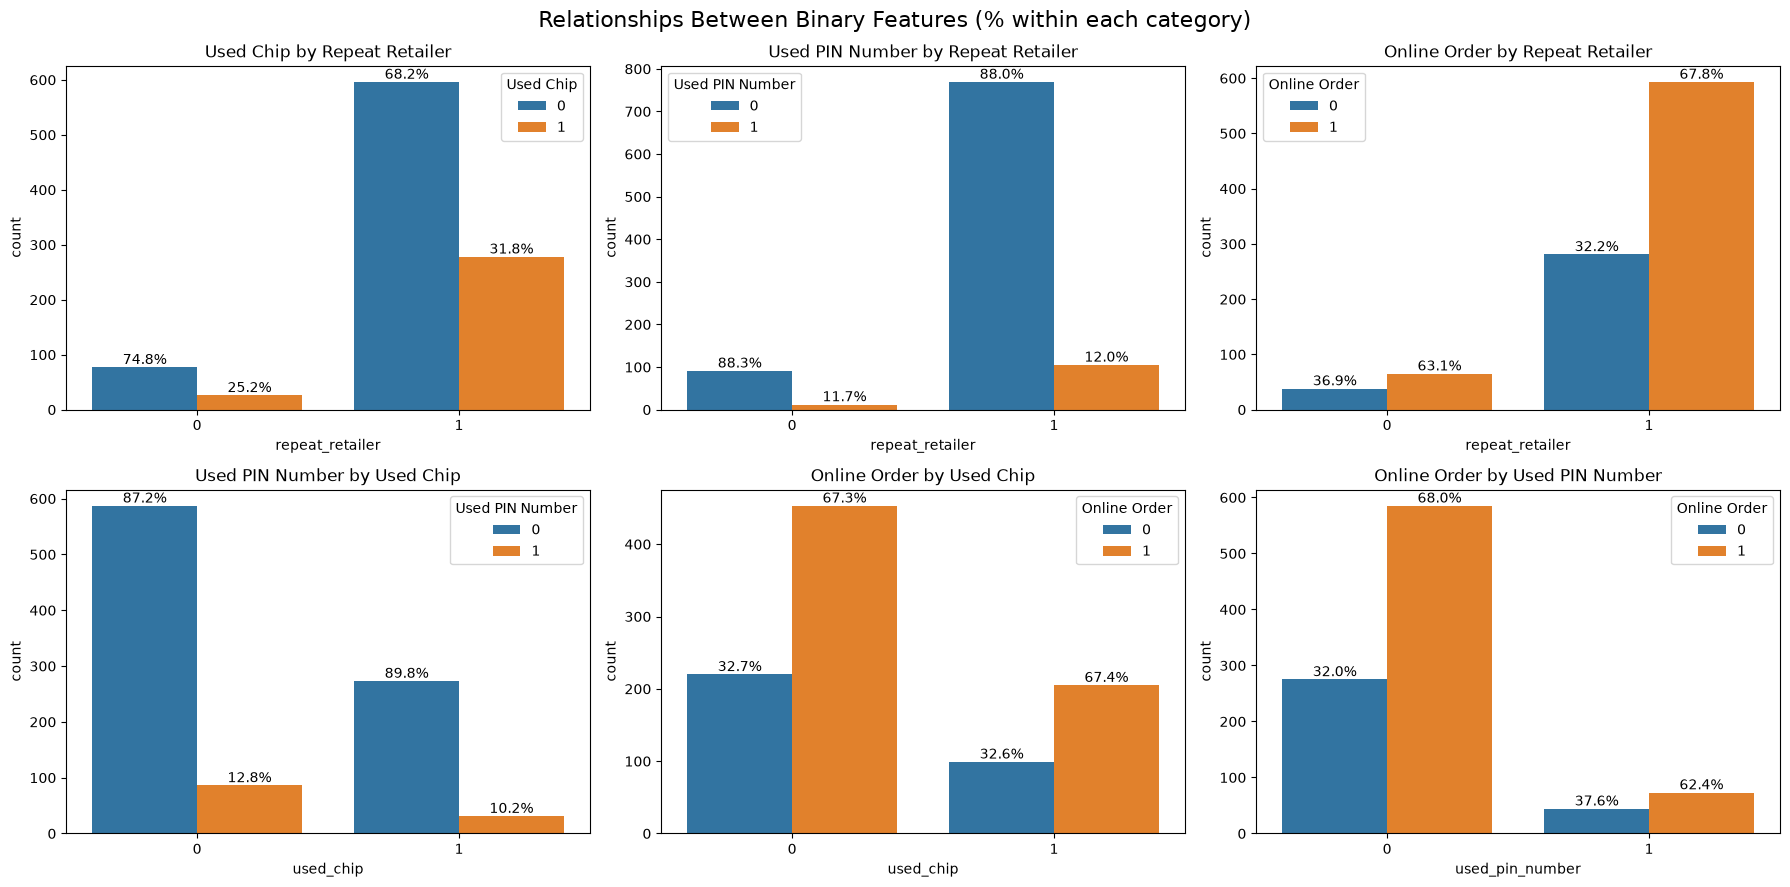

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (a, b) in zip(axes.flat, combinations(predictors, 2)):
    countplot_with_pct(ax, a, b)
fig.suptitle('Relationships Between Binary Features (% within each category)', fontsize=16)
plt.tight_layout()
plt.show()

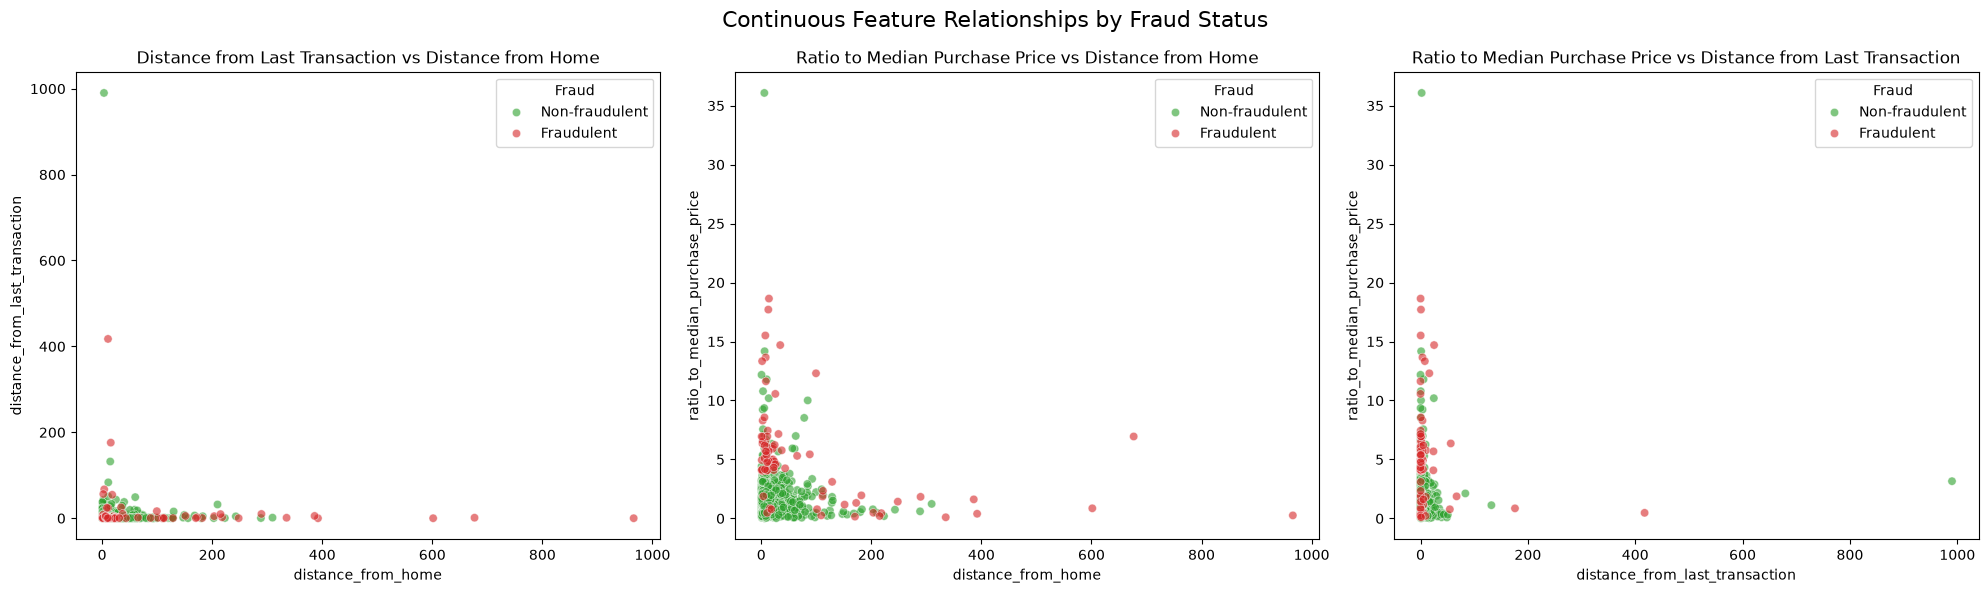

In [11]:
# sorting draws the rare fraud points last so they aren't hidden
scatter_data = data_clean.sort_values('fraud').assign(fraud_label=lambda d: d['fraud'].map(fraud_labels))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (a, b) in zip(axes, combinations(continuous, 2)):
    sns.scatterplot(data=scatter_data, x=a, y=b, hue='fraud_label', hue_order=list(fraud_palette),
                    palette=fraud_palette, alpha=0.6, ax=ax)
    ax.set_title(f'{names[b]} vs {names[a]}')
    ax.legend(title='Fraud')
fig.suptitle('Continuous Feature Relationships by Fraud Status', fontsize=16)
plt.tight_layout()
plt.show()

Prompt: Let us now build an ML classifier for detecting fraudulent transactions. to understand ML fundamentals, we will first have a simple model that always predict 'not-fraud' this will show that it will have a high accuracy because of the imbalanced dataset. then we will compare multiple evaluation metrics (including confusion matrices) with a k-NN approach. a bar chart would be a good visual for the different evaluation metrics between the 2 approaches.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

X = data_clean.drop(columns='fraud')
y = data_clean['fraud']

# stratify keeps the ~8% fraud rate the same in both splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f'Train: {X_train.shape[0]} rows ({y_train.sum()} fraudulent)')
print(f'Test:  {X_test.shape[0]} rows ({y_test.sum()} fraudulent)')

Train: 732 rows (57 fraudulent)
Test:  245 rows (19 fraudulent)


In [13]:
baseline = DummyClassifier(strategy='constant', constant=0)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(f'Baseline accuracy: {accuracy_score(y_test, baseline_pred):.3f}')

Baseline accuracy: 0.922


Prompt: lets use the elbow method to find optimal k - before selecting k value

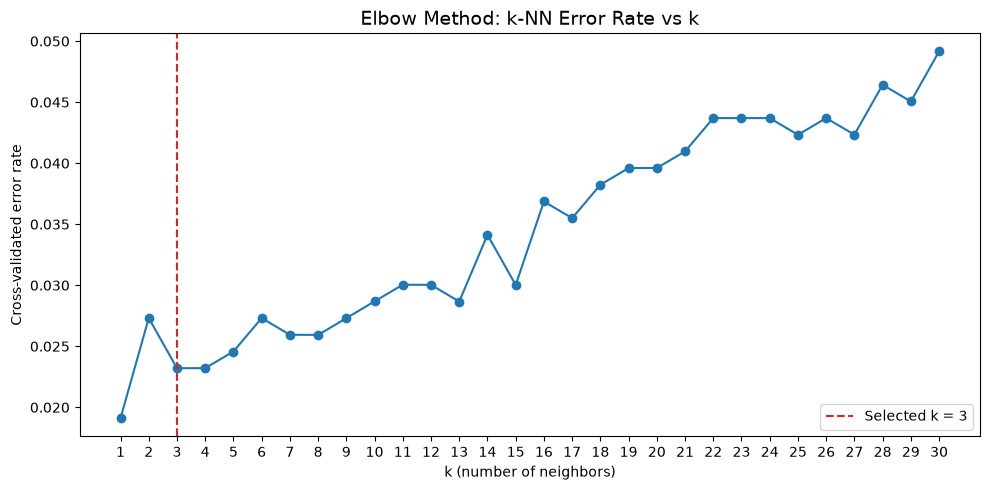

Selected k: 3 (CV error rate 0.0232)


In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# cross-validate on the training set only so the test set stays unseen until final evaluation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = range(1, 31)
error_rates = []
for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    error_rates.append(1 - cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy').mean())

elbow = pd.Series(error_rates, index=k_values)
# k=1 just copies the single nearest point and overfits; odd k avoids tied votes between the two classes
best_k = elbow[(elbow.index > 1) & (elbow.index % 2 == 1)].idxmin()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(elbow.index, elbow.values, marker='o')
ax.axvline(best_k, color='tab:red', linestyle='--', label=f'Selected k = {best_k}')
ax.set_xticks(list(k_values))
ax.set_xlabel('k (number of neighbors)')
ax.set_ylabel('Cross-validated error rate')
ax.set_title('Elbow Method: k-NN Error Rate vs k', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

print(f'Selected k: {best_k} (CV error rate {elbow[best_k]:.4f})')

In [15]:
# k-NN is distance-based, so features must be on the same scale
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print(f'k-NN accuracy: {accuracy_score(y_test, knn_pred):.3f}')

k-NN accuracy: 0.971


In [16]:
predictions = {
    'Always Non-fraudulent': baseline_pred,
    f'k-NN (k={best_k})': knn_pred,
}

metrics = pd.DataFrame({
    name: {
        'Accuracy': accuracy_score(y_test, pred),
        # the baseline never predicts fraud, so precision would divide by zero
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred),
    }
    for name, pred in predictions.items()
})
metrics.round(3)

,Always Non-fraudulent,k-NN (k=3)
Accuracy,0.922,0.971
Precision,0.000,0.875
Recall,0.000,0.737
F1 Score,0.000,0.800


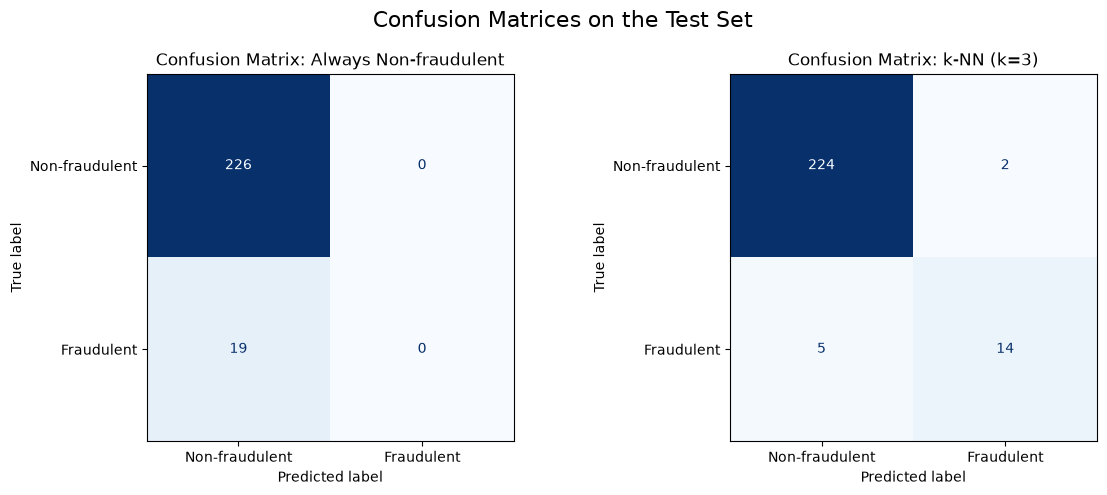

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=list(fraud_labels.values())).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix: {name}')
fig.suptitle('Confusion Matrices on the Test Set', fontsize=16)
plt.tight_layout()
plt.show()

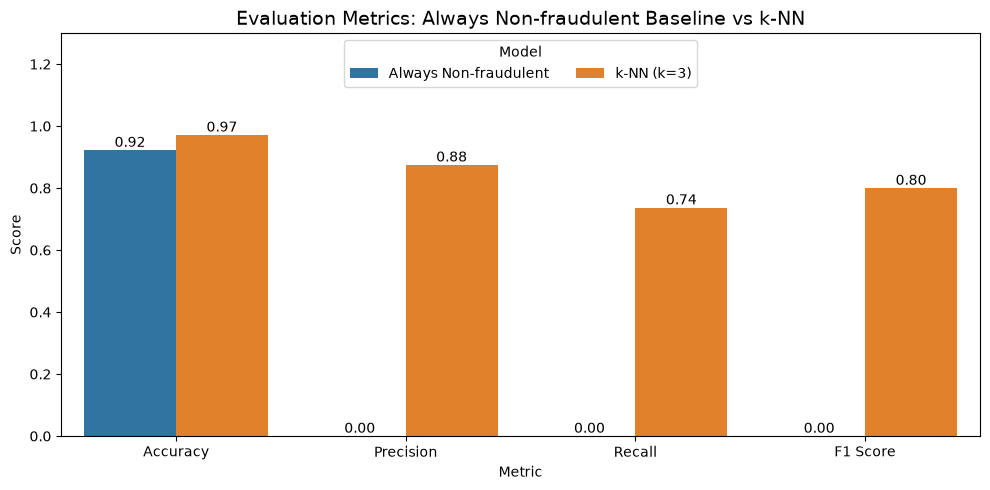

In [18]:
metrics_long = metrics.reset_index(names='Metric').melt(id_vars='Metric', var_name='Model', value_name='Score')

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=metrics_long, x='Metric', y='Score', hue='Model', ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
ax.set_ylim(0, 1.3)
ax.legend(title='Model', loc='upper center', ncol=2)
ax.set_title('Evaluation Metrics: Always Non-fraudulent Baseline vs k-NN', fontsize=14)
plt.tight_layout()
plt.show()

Prompt: let's now create a 3d visualization for k-nn predictions - using the 3 best features for predicting a fraudulent transaction

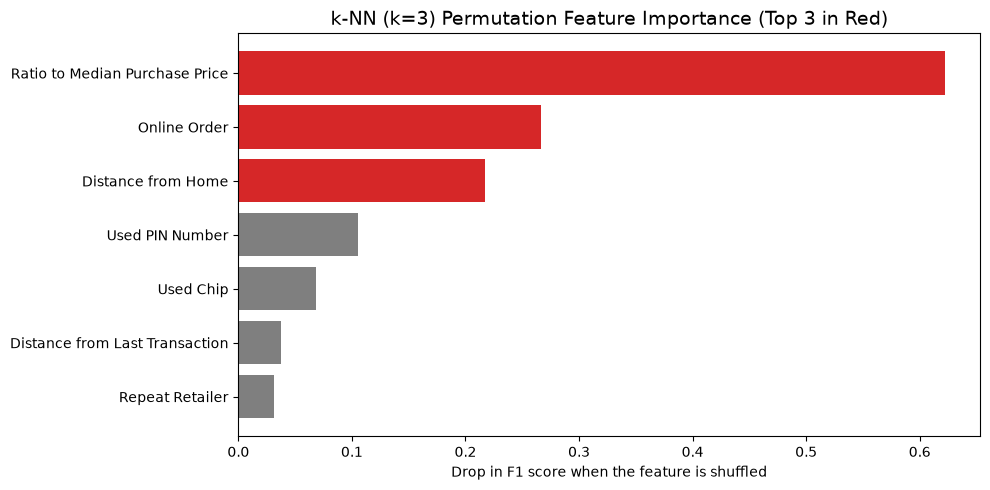

Top 3 features: ['Ratio to Median Purchase Price', 'Online Order', 'Distance from Home']


In [19]:
from sklearn.inspection import permutation_importance

# importance measured on training data so the test set stays unseen
importance = permutation_importance(knn, X_train, y_train, scoring='f1', n_repeats=20, random_state=42)
importance = pd.Series(importance.importances_mean, index=X_train.columns).sort_values()
top3 = importance.index[::-1][:3].tolist()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([names[c] for c in importance.index], importance.values,
        color=['tab:red' if c in top3 else 'tab:gray' for c in importance.index])
ax.set_xlabel('Drop in F1 score when the feature is shuffled')
ax.set_title(f'k-NN (k={best_k}) Permutation Feature Importance (Top 3 in Red)', fontsize=14)
plt.tight_layout()
plt.show()

print('Top 3 features:', [names[c] for c in top3])

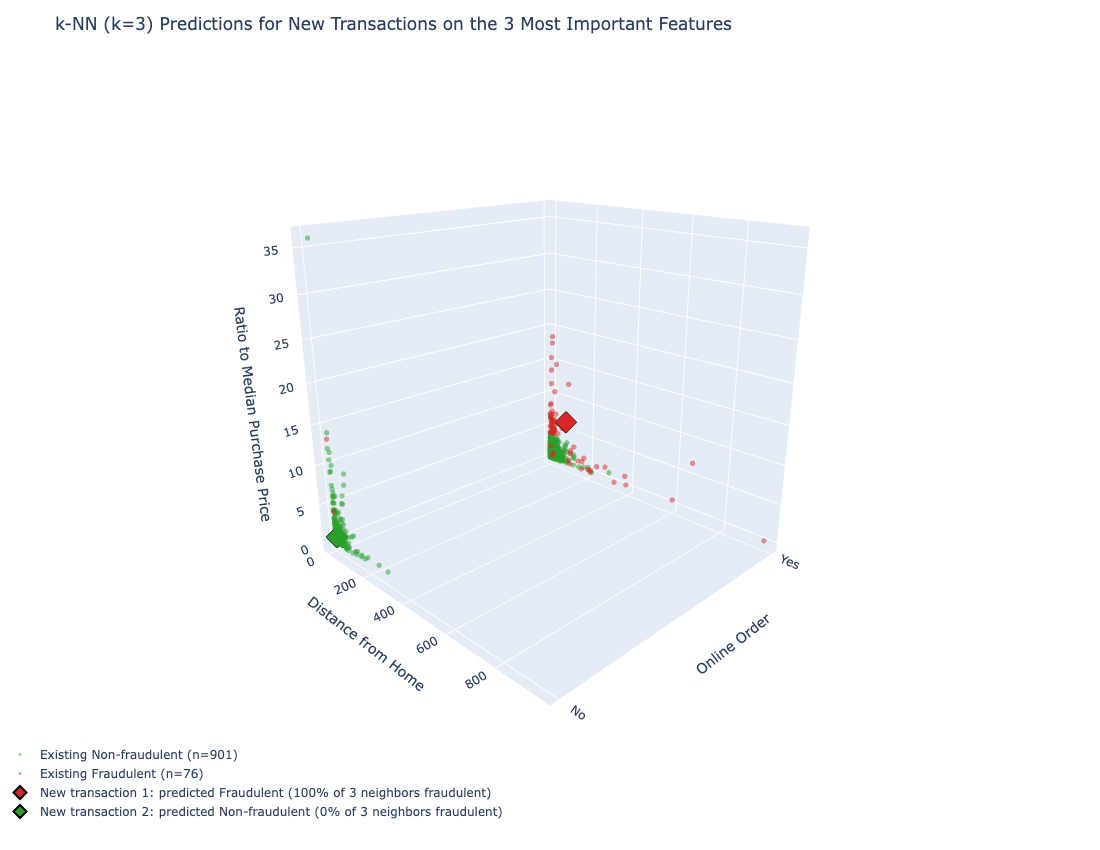

In [20]:
import plotly.graph_objects as go

x_col, y_col, z_col = 'distance_from_home', 'online_order', 'ratio_to_median_purchase_price'
plotly_colors = {'Non-fraudulent': '#2ca02c', 'Fraudulent': '#d62728'}

new_transactions = pd.DataFrame([
    {'distance_from_home': 85.0, 'distance_from_last_transaction': 1.5, 'ratio_to_median_purchase_price': 6.5,
     'repeat_retailer': 1.0, 'used_chip': 0.0, 'used_pin_number': 0.0, 'online_order': 1.0},
    {'distance_from_home': 6.0, 'distance_from_last_transaction': 0.4, 'ratio_to_median_purchase_price': 0.9,
     'repeat_retailer': 1.0, 'used_chip': 1.0, 'used_pin_number': 1.0, 'online_order': 0.0},
], columns=X.columns)
new_pred = knn.predict(new_transactions)
new_fraud_share = knn.predict_proba(new_transactions)[:, 1]

hover = (f'{names[x_col]}: %{{x:.1f}}<br>{names[y_col]}: %{{y}}<br>'
         f'{names[z_col]}: %{{z:.2f}}')

fig = go.Figure()
for value, label in fraud_labels.items():
    pts = data_clean[data_clean['fraud'] == value]
    fig.add_trace(go.Scatter3d(
        x=pts[x_col], y=pts[y_col], z=pts[z_col], mode='markers',
        name=f'Existing {label} (n={len(pts)})',
        marker=dict(size=3, color=plotly_colors[label], opacity=0.5),
        hovertemplate=hover))

for i, (pred, share) in enumerate(zip(new_pred, new_fraud_share)):
    label = fraud_labels[pred]
    row = new_transactions.iloc[i]
    fig.add_trace(go.Scatter3d(
        x=[row[x_col]], y=[row[y_col]], z=[row[z_col]], mode='markers',
        name=f'New transaction {i + 1}: predicted {label} ({share:.0%} of {best_k} neighbors fraudulent)',
        marker=dict(size=10, color=plotly_colors[label], symbol='diamond', line=dict(color='black', width=2)),
        hovertemplate=hover))

fig.update_layout(
    title=f'k-NN (k={best_k}) Predictions for New Transactions on the 3 Most Important Features',
    scene=dict(
        xaxis_title=names[x_col],
        yaxis=dict(title=names[y_col], tickvals=[0, 1], ticktext=['No', 'Yes']),
        zaxis_title=names[z_col],
    ),
    scene_camera=dict(eye=dict(x=1.6, y=-1.6, z=0.8)),
    legend=dict(title='Click a legend item to show or hide it', orientation='h', x=0, y=-0.05, yanchor='top'),
    margin=dict(l=0, r=0, t=60, b=0),
    height=800,
)
# render inline as a cell output; outside a kernel plotly would otherwise fall back to opening a browser
fig.show(renderer='vscode+notebook_connected')

# GitHub's notebook preview can't run JavaScript, so also save a static snapshot it can display
from IPython.display import Image, display
static_fig = go.Figure(fig).update_layout(legend=dict(title=None, orientation='v', x=0, y=0, yanchor='top'),
                                          margin=dict(b=110))
display(Image(static_fig.to_image(format='png', width=1100, height=850)))